<a href="https://colab.research.google.com/github/beckymaldonado/CECS-101-Digital-Portfolio/blob/main/Group_Project_Data_Cleaning_and_EDAEDA_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
##Data Cleaning and EDA

#0. Notebook Metabata
# Emily Canty
# Becky Maldonado
# Tol Swindell
# Ask a Manager Salary Survery 2021
# https://docs.google.com/spreadsheets/d/1IPS5dBSGtwYVbjsfbaMCYIWnOuRmJcbequohNxCyGVw/edit?resourcekey=&gid=1625408792#gid=1625408792
# October 30, 2026



In [2]:
##1. Load Data
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("salary_survey.csv")
df

,Timestamp,How old are you?,What industry do you work in?,Job title,"If your job title needs additional context, please clarify here:","What is your annual salary? (You'll indicate the currency in a later question. If you are part-time or hourly, please enter an annualized equivalent -- what you would earn if you worked the job 40 hours a week, 52 weeks a year.)","How much additional monetary compensation do you get, if any (for example, bonuses or overtime in an average year)? Please only include monetary compensation here, not the value of benefits.",Please indicate the currency,"If ""Other,"" please indicate the currency here:","If your income needs additional context, please provide it here:",What country do you work in?,"If you're in the U.S., what state do you work in?",What city do you work in?,How many years of professional work experience do you have overall?,How many years of professional work experience do you have in your field?,What is your highest level of education completed?,What is your gender?,What is your race? (Choose all that apply.)
0,4/27/2021 11:02,25-34,Education (Higher Education),Research and Instruction Librarian,NaN,"55,000",0.0,USD,NaN,NaN,United States,Massachusetts,Boston,5-7 years,5-7 years,Master's degree,Woman,White
1,4/27/2021 11:02,25-34,Computing or Tech,Change & Internal Communications Manager,NaN,"54,600",4000.0,GBP,NaN,NaN,United Kingdom,NaN,Cambridge,8 - 10 years,5-7 years,College degree,Non-binary,White
2,4/27/2021 11:02,25-34,"Accounting, Banking & Finance",Marketing Specialist,NaN,"34,000",NaN,USD,NaN,NaN,US,Tennessee,Chattanooga,2 - 4 years,2 - 4 years,College degree,Woman,White
3,4/27/2021 11:02,25-34,Nonprofits,Program Manager,NaN,"62,000",3000.0,USD,NaN,NaN,USA,Wisconsin,Milwaukee,8 - 10 years,5-7 years,College degree,Woman,White
4,4/27/2021 11:02,25-34,"Accounting, Banking & Finance",Accounting Manager,NaN,"60,000",7000.0,USD,NaN,NaN,US,South Carolina,Greenville,8 - 10 years,5-7 years,College degree,Woman,White
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28240,10/13/2026 15:19,18-24,Hospitality & Events,Event staff,NaN,35000,NaN,USD,NaN,NaN,America,Florida,Naples,2 - 4 years,2 - 4 years,Some college,Man,White
28241,10/13/2026 15:27,18-24,Computing or Tech,student,NaN,0,NaN,USD,NaN,NaN,US,Michigan,East Lansing,2 - 4 years,2 - 4 years,High School,Man,Asian or Asian American
28242,10/13/2026 21:00,18-24,Social Work,tutor,NaN,31200,0.0,USD,NaN,NaN,United States,Michigan,Lansing,2 - 4 years,1 year or less,Some college,Man,Middle Eastern or Northern African
28243,10/15/2026 13:38,18-24,Hospitality & Events,Community Associate,NaN,37650,NaN,USD,NaN,NaN,U.S.A,Nevada,Las Vegas,5-7 years,5-7 years,College degree,Woman,Black or African American


Dataset is from Ask a Manager's Salary Survery (2021) which contains salary and job infomration. Dataset contains 28245 rows and 18 columns.

In [ ]:
##2. Initial Data Overview (EDA with uncleaned data)



In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28245 entries, 0 to 28244
Data columns (total 18 columns):
 #   Column                                                                                                                                                                                                                                Non-Null Count  Dtype  
---  ------                                                                                                                                                                                                                                --------------  -----  
 0   Timestamp                                                                                                                                                                                                                             28245 non-null  object 
 1   How old are you?                                                                                             

In [5]:
df.describe(include="all")
df.shape

(28245, 18)

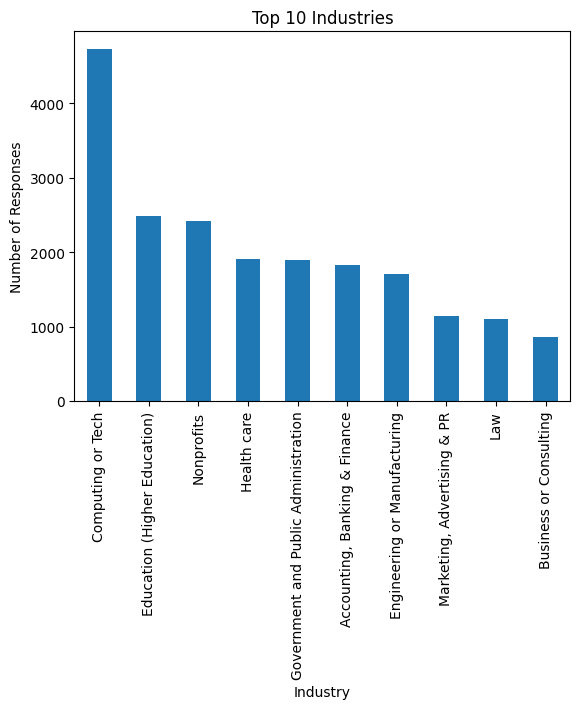

In [6]:
df["What industry do you work in?"].value_counts().head(10).plot(kind="bar")
plt.xlabel("Industry")
plt.ylabel("Number of Responses")
plt.title("Top 10 Industries")
plt.show()

In [7]:
df.columns.tolist()

['Timestamp',
 'How old are you?',
 'What industry do you work in?',
 'Job title',
 'If your job title needs additional context, please clarify here:',
 "What is your annual salary? (You'll indicate the currency in a later question. If you are part-time or hourly, please enter an annualized equivalent -- what you would earn if you worked the job 40 hours a week, 52 weeks a year.)",
 'How much additional monetary compensation do you get, if any (for example, bonuses or overtime in an average year)? Please only include monetary compensation here, not the value of benefits.',
 'Please indicate the currency',
 'If "Other," please indicate the currency here: ',
 'If your income needs additional context, please provide it here:',
 'What country do you work in?',
 "If you're in the U.S., what state do you work in?",
 'What city do you work in?',
 'How many years of professional work experience do you have overall?',
 'How many years of professional work experience do you have in your field?',

In [8]:
plot_data = df[df["Please indicate the currency"] == "USD"].copy()

In [9]:
salary_column = plot_data.columns[5]
plot_data["Salary"] = pd.to_numeric(
    plot_data[salary_column].str.replace(",","", regex=False),
    errors="coerce"
)

In [10]:
plot_data["Salary"].head()

,Salary
0,55000
2,34000
3,62000
4,60000
5,62000


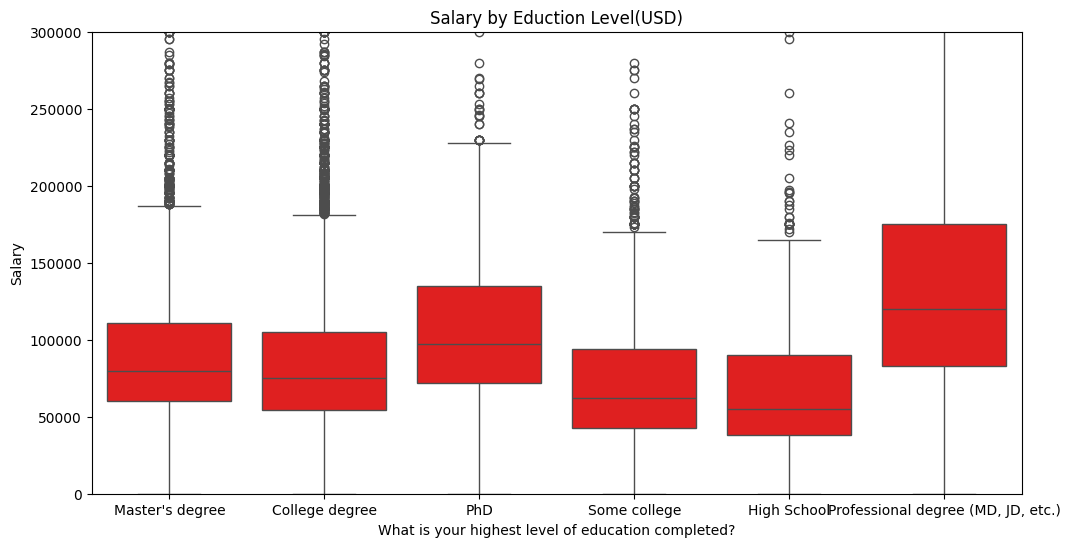

In [11]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=plot_data,
    x="What is your highest level of education completed?",
    y="Salary",
    color="red"
)
plt.title("Salary by Eduction Level(USD)")
plt.ylim(0, 300000)
plt.show()

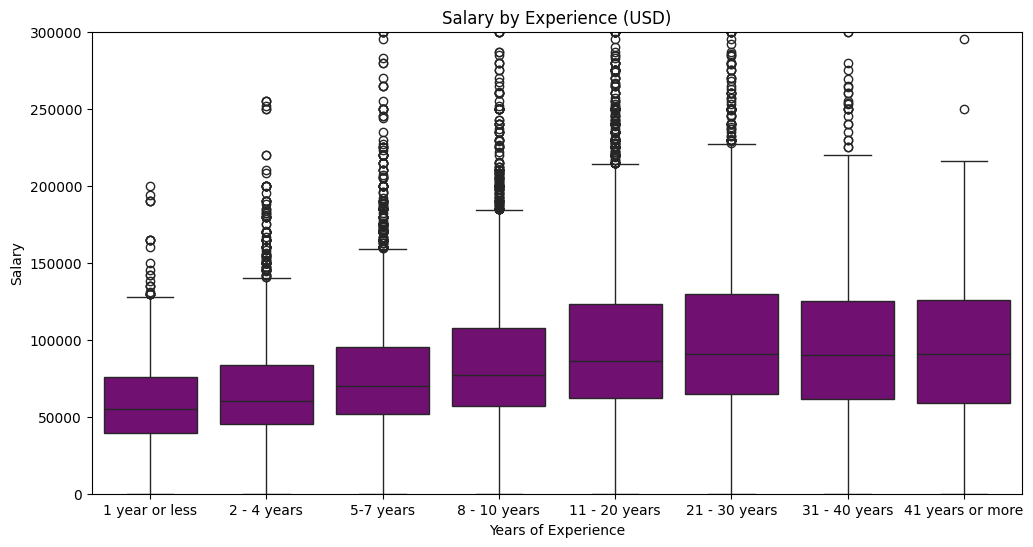

In [12]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=plot_data,
    x="How many years of professional work experience do you have overall?",
    y="Salary",
    color="purple",
    order=["1 year or less", "2 - 4 years", "5-7 years", "8 - 10 years", "11 - 20 years", "21 - 30 years", "31 - 40 years", "41 years or more"]

)

plt.title("Salary by Experience (USD)")
plt.xlabel("Years of Experience")
plt.ylim(0, 300000)
plt.show()

- I had expected Healthcare to have the most survey responses
- Potential Outliers with the Box Plots.
- Professional degrees have the highest median in the salary plot
- Respondents with more experiences generally had higher median salaries, but were similar among the more experienced groups.
- 21-30 years group appears to have the highest median.
  

In [ ]:
##3. Data Quality Issues Logged

#Issue #1: Inconsistent spacing in experience ranges
- Location: "How many years of professional work experience do you have overall?"
- Type of Issue: Formatting inconsistency with 5-7 years.  There is no space in between the hyphen 5-7 years, while the others have a space between the hyphen.
- Evidence: While completing the box plot I noticed the discrepancy when I added a space around the hyphen for 5-7 years and no box plot appeared. Reviewed the dataset I found the issue that in the dataset for 5-7 years there is no space around the hyphen.
- Potential impact on analysis/bias concerns: If the information in the plot code does not match the dataset exactly, the 5-7 years group will not appear in the plot set while leaving out the correct comparsion/information.   

#Issue #2: Missing Entries

In [13]:
df.isnull().sum()

,0
Timestamp,0
How old are you?,0
What industry do you work in?,87
Job title,6
"If your job title needs additional context, please clarify here:",20950
"What is your annual salary? (You'll indicate the currency in a later question. If you are part-time or hourly, please enter an annualized equivalent -- what you would earn if you worked the job 40 hours a week, 52 weeks a year.)",0
"How much additional monetary compensation do you get, if any (for example, bonuses or overtime in an average year)? Please only include monetary compensation here, not the value of benefits.",7389
Please indicate the currency,0
"If ""Other,"" please indicate the currency here:",28018
"If your income needs additional context, please provide it here:",25192


#2. Missing responses
- Location: There is 12 out of 18 columns that contain missing responses
- Type of Issue: Missing value
- Evidence: Ran the code df.isnull().sum() the ouput above shows the number of missing responses in each column
- Potential impact on analysis/bias concern: Missing responses can limit comparsions and somtimes cause bias. As some blanks are expected if some questions were optional or do not apply to everyone.  

#3 Possible Salary outliers
- Location: Salary values in the data used for education and experience box plots
-  Type of Issues: Possible outliers
-  Evidence: The box plots from Section 2 shows dots above the whiskers leading to a highere salary within those groups
-  Potential impact: The high salaries can raise the average and affect the comparsions.  Would need to further review since they could be valid and not errors.


### Issue #4: Possible Duplicate Responses

- **Location:** Entire dataset
- **Type of Issue:** Possible duplicate rows
- **Evidence:** We will use `df.duplicated().sum()` to check whether the dataset contains identical responses.
- **Potential impact on analysis/bias concerns:** Duplicate responses could cause certain salary information to be counted more than once, which could affect our results.



### Issue #5: Invalid Salary Values

- **Location:** Annual salary column
- **Type of Issue:** Missing, non-numeric, zero, or negative salary values
- **Evidence:** We will convert salaries to numeric values and check for missing or invalid entries.
- **Potential impact on analysis/bias concerns:** Invalid salary values could affect our calculations and make salary comparisons less accurate.



### Issue #6: Inconsistent Industry Formatting

- **Location:** "What industry do you work in?"
- **Type of Issue:** Possible inconsistent spacing or formatting
- **Evidence:** We will check industry names for extra spaces and inconsistent formatting.
- **Potential impact on analysis/bias concerns:** Inconsistent industry names could cause the same industry to be counted in separate categories, making comparisons less accurate.



## 4. Data Cleaning Actions

We created a copy of the original dataset so that we could clean the data without changing the original information. We addressed missing values, inconsistent formatting, possible duplicates, invalid salaries, and outliers.


In [14]:

# Create a copy of the original dataset
clean_df = df.copy()

print("Original dataset shape:", df.shape)

# ISSUE 1: Inconsistent experience ranges
experience_col = "How many years of professional work experience do you have overall?"

before = clean_df[experience_col].copy()

clean_df[experience_col] = (
    clean_df[experience_col]
    .astype("string")
    .str.strip()
    .str.replace(r"\s*-\s*", "-", regex=True)
)

print("\nIssue 1: Experience values changed:",
      (before.astype("string") !=
       clean_df[experience_col]).fillna(False).sum())


# ISSUE 2: Missing values
print("\nIssue 2: Missing values before cleaning:")
print(clean_df.isnull().sum())

for col in ["What industry do you work in?", "Job title"]:
    clean_df[col] = (
        clean_df[col]
        .replace(r"^\s*$", pd.NA, regex=True)
        .fillna("Unknown")
    )

print("\nMissing industry and job titles filled")


# ISSUE 3: Salary outliers and salary conversion
salary_col = "What is your annual salary?"

# Use exact salary column if available
# Otherwise find the annual salary question
if salary_col not in clean_df.columns:
    salary_col = next(
        c for c in clean_df.columns
        if "annual salary" in c.lower()
    )

clean_df["Salary"] = pd.to_numeric(
    clean_df[salary_col]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("$", "", regex=False)
    .str.strip(),
    errors="coerce"
)

usd_df = clean_df[
    clean_df["Please indicate the currency"]
    .astype("string").str.strip().str.upper() == "USD"
].copy()

Q1 = usd_df["Salary"].quantile(0.25)
Q3 = usd_df["Salary"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = usd_df[
    (usd_df["Salary"] < lower_bound) |
    (usd_df["Salary"] > upper_bound)
]

print("\nIssue 3: Possible USD salary outliers:",
      len(outliers))


# ISSUE 4: Duplicate rows
duplicates = clean_df.duplicated().sum()

print("\nIssue 4: Exact duplicate rows:", duplicates)

# Keep duplicates because identical answers
# may come from different respondents.


# ISSUE 5: Invalid salaries
invalid_salaries = (
    clean_df["Salary"].isna() |
    (clean_df["Salary"] <= 0)
).sum()

print("\nIssue 5: Invalid salaries:", invalid_salaries)

clean_df = clean_df[
    clean_df["Salary"].notna() &
    (clean_df["Salary"] > 0)
].copy()


# ISSUE 6: Inconsistent industry formatting
industry_col = "What industry do you work in?"

before_industry = clean_df[industry_col].copy()

clean_df[industry_col] = (
    clean_df[industry_col]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

changed = (
    before_industry.astype("string") !=
    clean_df[industry_col]
).fillna(False).sum()

print("\nIssue 6: Industry values changed:", changed)

print("\nCleaning completed")
print("Cleaned dataset shape:", clean_df.shape)


Original dataset shape: (28245, 18)

Issue 1: Experience values changed: 22634

Issue 2: Missing values before cleaning:
Timestamp                                                                                                                                                                                                                                   0
How old are you?                                                                                                                                                                                                                            0
What industry do you work in?                                                                                                                                                                                                              87
Job title                                                                                                                                                            


### Cleaning Decisions and Explanations

**Issue #1: Inconsistent Experience Ranges**

We standardized the spacing in the experience categories so they follow the same format. This helps make comparisons more consistent.

**Issue #2: Missing Values**

We replaced missing industry and job title responses with "Unknown" instead of deleting the entire row. This allows us to keep other useful information.

**Issue #3: Salary Outliers**

We used the interquartile range (IQR) method to identify possible salary outliers. We kept these values because unusually high salaries are not necessarily errors.

**Issue #4: Duplicate Responses**

We checked for exact duplicate rows. We chose not to automatically remove them because different people could have identical survey responses.

**Issue #5: Invalid Salary Values**

We converted salary responses to numeric values and removed rows with missing, zero, or negative salaries. This helps ensure that the salary calculations use valid positive amounts.

**Issue #6: Inconsistent Industry Formatting**

We removed extra spaces from industry names to make the categories more consistent for comparisons.



## 5. Exploratory Data Analysis with Cleaned Data

We created visualizations using the cleaned dataset to examine the relationship between education, professional experience, and annual salary. We focused on salaries reported in USD to avoid comparing different currencies.


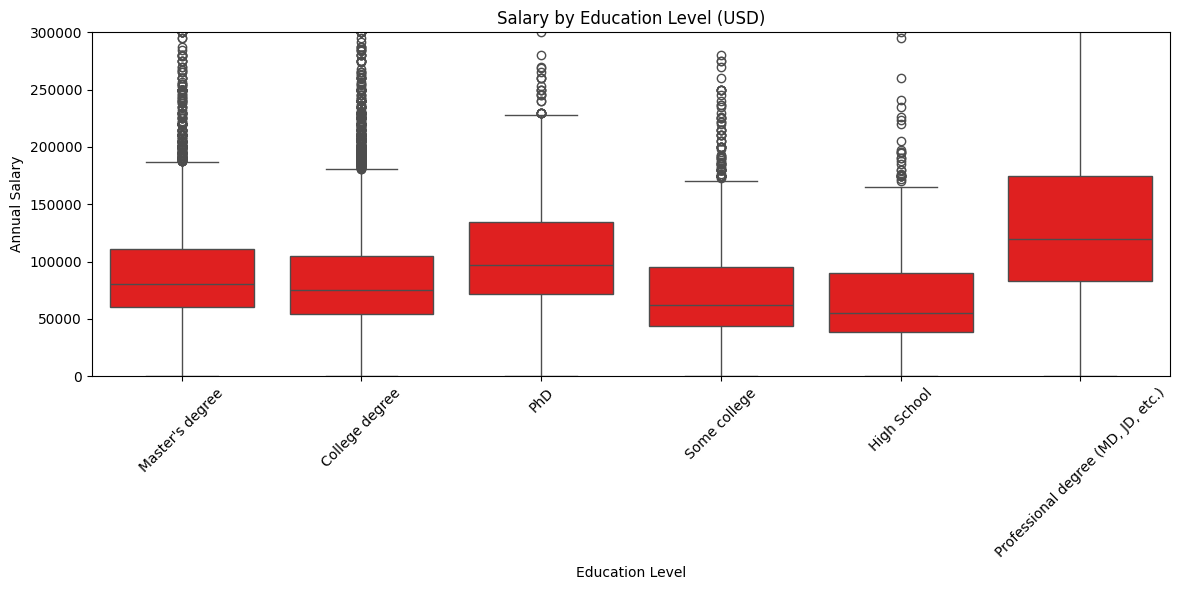

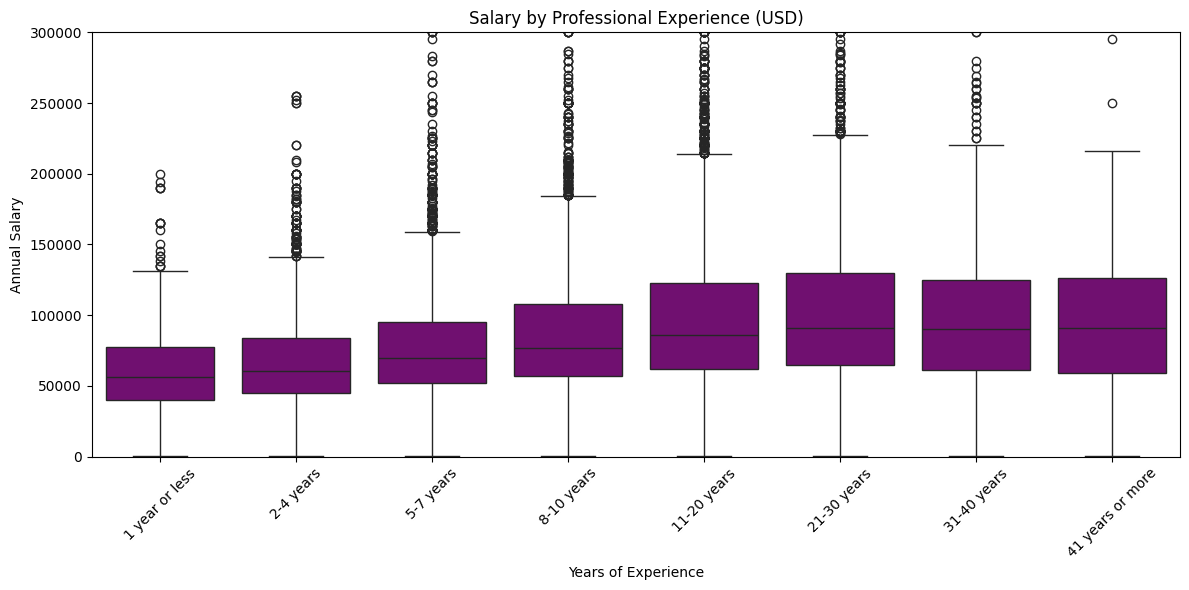

In [15]:

# Use the cleaned dataset for USD salaries
plot_clean = clean_df[
    clean_df["Please indicate the currency"]
    .astype("string").str.strip().str.upper() == "USD"
].copy()

# Visualization 1: Salary by education
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=plot_clean,
    x="What is your highest level of education completed?",
    y="Salary",
    color="red"
)

plt.title("Salary by Education Level (USD)")
plt.xlabel("Education Level")
plt.ylabel("Annual Salary")
plt.xticks(rotation=45)
plt.ylim(0, 300000)
plt.tight_layout()
plt.show()


# Visualization 2: Salary by experience
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=plot_clean,
    x=experience_col,
    y="Salary",
    color="purple",
    order=[
        "1 year or less",
        "2-4 years",
        "5-7 years",
        "8-10 years",
        "11-20 years",
        "21-30 years",
        "31-40 years",
        "41 years or more"
    ]
)

plt.title("Salary by Professional Experience (USD)")
plt.xlabel("Years of Experience")
plt.ylabel("Annual Salary")
plt.xticks(rotation=45)
plt.ylim(0, 300000)
plt.tight_layout()
plt.show()



### Observations from Cleaned Data

- The education graph allows us to compare median salaries across education levels.
- The experience graph allows us to examine whether salaries generally increase with years of professional experience.
- Possible salary outliers remain visible because we did not automatically remove unusually high salaries.
- We will compare these graphs with the original visualizations to determine whether cleaning changed the patterns.



## 6. Final Data Quality Check

We reviewed the cleaned dataset to compare its size with the original dataset and check for remaining missing values and duplicate responses.


In [16]:

# Compare original and cleaned datasets
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)

# Check missing values
print("\nRemaining missing values:")
print(clean_df.isnull().sum())

# Check duplicates
print("\nRemaining duplicate rows:")
print(clean_df.duplicated().sum())

# Salary statistics
print("\nSalary summary statistics:")
print(clean_df["Salary"].describe())

# Preview cleaned data
clean_df.head()


Original dataset shape: (28245, 18)
Cleaned dataset shape: (28209, 19)

Remaining missing values:
Timestamp                                                                                                                                                                                                                                   0
How old are you?                                                                                                                                                                                                                            0
What industry do you work in?                                                                                                                                                                                                               0
Job title                                                                                                                                                                                   

,Timestamp,How old are you?,What industry do you work in?,Job title,"If your job title needs additional context, please clarify here:","What is your annual salary? (You'll indicate the currency in a later question. If you are part-time or hourly, please enter an annualized equivalent -- what you would earn if you worked the job 40 hours a week, 52 weeks a year.)","How much additional monetary compensation do you get, if any (for example, bonuses or overtime in an average year)? Please only include monetary compensation here, not the value of benefits.",Please indicate the currency,"If ""Other,"" please indicate the currency here:","If your income needs additional context, please provide it here:",What country do you work in?,"If you're in the U.S., what state do you work in?",What city do you work in?,How many years of professional work experience do you have overall?,How many years of professional work experience do you have in your field?,What is your highest level of education completed?,What is your gender?,What is your race? (Choose all that apply.),Salary
0,4/27/2021 11:02,25-34,Education (Higher Education),Research and Instruction Librarian,NaN,"55,000",0.0,USD,NaN,NaN,United States,Massachusetts,Boston,5-7 years,5-7 years,Master's degree,Woman,White,55000
1,4/27/2021 11:02,25-34,Computing or Tech,Change & Internal Communications Manager,NaN,"54,600",4000.0,GBP,NaN,NaN,United Kingdom,NaN,Cambridge,8-10 years,5-7 years,College degree,Non-binary,White,54600
2,4/27/2021 11:02,25-34,"Accounting, Banking & Finance",Marketing Specialist,NaN,"34,000",NaN,USD,NaN,NaN,US,Tennessee,Chattanooga,2-4 years,2 - 4 years,College degree,Woman,White,34000
3,4/27/2021 11:02,25-34,Nonprofits,Program Manager,NaN,"62,000",3000.0,USD,NaN,NaN,USA,Wisconsin,Milwaukee,8-10 years,5-7 years,College degree,Woman,White,62000
4,4/27/2021 11:02,25-34,"Accounting, Banking & Finance",Accounting Manager,NaN,"60,000",7000.0,USD,NaN,NaN,US,South Carolina,Greenville,8-10 years,5-7 years,College degree,Woman,White,60000



### Group Member Contributions

- Emily Canty: For this part of the project, I worked on cleaning up our dataset and making it easier to use. I checked for missing information, duplicate responses, and salary values that seemed too high or too low. I also fixed some formatting issues, made the experience ranges and industry names more consistent, and removed salary values that weren't valid for our analysis. After that, I made graphs to compare salaries based on education and work experience. I also went back through the data to make sure the cleaning steps worked. Overall, this helped us get our data ready for the next part of the project.
- Becky Maldonado: I worked on loading and exploring the Ask a Manager Salary Survey dataset.  I reviewed the dataset, which contained 28,245 rows and 18 columns.  I created a bar chart showing the top 10 industries and box plots comparing salaries by education level and years of work experience. I also identified three data quality issues: Inconsistent spacing in experience ranges, missing response and possible salary outliers.  Also documented these issues, explained how I found them and how they could affect the analysis.
- Tol Swindell: [Sections completed]



## 7. Expected Next Steps for Analysis

Our next step is to analyze how education level, years of professional experience, and industry relate to annual salary. We plan to compare salaries across these categories to identify trends and determine which factors appear to have the strongest relationships with earnings.

We also plan to create additional visualizations and calculate summary statistics to better understand the data. We will consider missing responses, possible outliers, and limitations of the survey when interpreting our results.
